![Banner](../images/03_06_banner_spatial_analysis_Segregation.png)






# Multigroup segregation indices






## Overview

Buffalo has more than two groups, and running a separate two-group index for every pair quickly
becomes hard to read (four groups already give six pairs). **Multigroup indices** answer one
question for all groups at once: how much does the composition of each tract differ from the
composition of the metro area?

This notebook follows the PySAL `segregation` tutorial on
[multigroup indices](https://pysal.org/segregation/tutorial.html) using
`geolattice.spatial_analysis.segregation`. Multigroup indices here use the four named groups
(`GROUPS`: white, Black, Hispanic, Asian); the heterogeneous `other` category is left out.

Topics:

- Diversity is not integration: metro-wide Simpson and entropy
- Theil's information theory index $H$ and each tract's share of it
- Multigroup dissimilarity and its link to the two-group index
- Pairwise dissimilarity matrices
- Local diversity maps
- Spatial (kernel-pooled) multigroup indices
- Validation against PySAL and confidence intervals






## Setup

The next cell finds the repository root, puts it on the import path, points `DATA` at
`Data/03_spatial_analysis/data_segregation/buffalo`, imports `geolattice.spatial_analysis.segregation` as `seg`, and loads
the data.

**Study area and data.** The Buffalo-Cheektowaga metropolitan area: Erie and Niagara counties,
New York (about 1.17 million people in 2020). Counts come from the U.S. Census Bureau decennial
censuses of 2000, 2010, and 2020, by census tract, for five mutually exclusive groups:

| Column | Census definition |
|---|---|
| `white` | Not Hispanic or Latino, White alone |
| `black` | Not Hispanic or Latino, Black or African American alone |
| `hispanic` | Hispanic or Latino (any race) |
| `asian` | Not Hispanic or Latino, Asian alone |
| `other` | Everyone else (other single races and two or more races) |

Tract boundaries change between censuses. To compare years on the same units, the 2000 and 2010
counts have been moved onto the 323 tracts of 2020 with dasymetric interpolation weighted by 2020
housing units; notebook 03_07_07 shows how. Tracts with fewer than 100 residents (water, parks,
the airport) are dropped. `Data/03_spatial_analysis/data_segregation/make_buffalo_data.py` rebuilds everything from
the Census files in `Data/03_spatial_analysis/data_segregation/`.

Two map helpers keep every map in the same frame: `add_context(ax)` draws the county outlines,
and `metro_and_core(...)` shows the whole metro area next to a 30 km window centred on the City
of Buffalo, where most tracts are small.

**Installation.** This notebook needs installation option 2 (core plus spatial analysis): `pip install "geolattice[analysis]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Display matplotlib figures inline in this Jupyter notebook.
%matplotlib inline

# Standard library imports for path setup and warning control.
import warnings  # silence noisy third-party warnings during demos
from pathlib import Path  # filesystem paths for locating sample data

# Third-party GIS / plotting / tabular stack used throughout the notebook.
import geopandas as gpd  # GeoDataFrame I/O for tracts and counties
import matplotlib.pyplot as plt  # figure and axes creation for maps
import numpy as np  # array ops for shares, norms, and masks
import pandas as pd  # tabular display of composition and indices
from IPython.display import display  # rich table previews in the notebook

# Hide library warnings so the notebook output stays readable.
warnings.filterwarnings("ignore")  # run this analysis or plotting step

# ===================================================================
# Setup for Buffalo metro segregation demos.
# Import GeoLattice, point DATA at Data/03_spatial_analysis/data_segregation/buffalo,
# import segregation as seg, load the tract panel, and define map helpers.
# ===================================================================

# The installed package lives in src/; the repository root is its parent.
import geolattice

ROOT = Path(geolattice.__file__).resolve().parents[1]
if not (ROOT / "Data").is_dir():
    raise FileNotFoundError("Could not find the GeoLattice repository root.")

# Buffalo metro sample data (Erie + Niagara tracts on a shared 2020 geography).
DATA = ROOT / "Data" / "03_spatial_analysis" / "data_segregation" / "buffalo"  # define DATA

# Segregation indices, local measures, profiles, and inference helpers.
from geolattice.spatial_analysis import segregation as seg

# Compact figures with top/right spines removed for a cleaner look.
plt.rcParams.update(  # run this analysis or plotting step
    {"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False}
)
GROUPS = ["white", "black", "hispanic", "asian"]  # main race/ethnicity count columns
ALL_GROUPS = GROUPS + ["other"]  # include residual other category in totals
YEARS = (2000, 2010, 2020)  # panel years available in the sample

# Panel on the 2020 tract geometry (2000 and 2010 interpolated onto it).
tracts = {  # define tracts
    2000: gpd.read_file(DATA / "tracts_2000_on2020.geojson"),  # 2000 counts on 2020 boundaries
    2010: gpd.read_file(DATA / "tracts_2010_on2020.geojson"),  # 2010 counts on 2020 boundaries
    2020: gpd.read_file(DATA / "tracts_2020.geojson"),  # native 2020 tracts
}
counties = gpd.read_file(DATA / "counties.geojson")  # Erie and Niagara outlines
CORE = (662_000, 4_738_000, 692_000, 4_768_000)  # 30 km window on the City of Buffalo (UTM 17N, m)
CITY_HALL = (673_249, 4_750_383)  # City Hall marker for the core window


def add_context(ax, core=False, labels=True):
    """Draw county boundaries and optionally zoom to the City of Buffalo window."""
    counties.boundary.plot(ax=ax, color="0.25", lw=0.8)  # county outlines for context
    if core:  # apply the city-window zoom when requested
        ax.set_xlim(CORE[0], CORE[2])  # zoom to city window
        ax.set_ylim(CORE[1], CORE[3])  # run this analysis or plotting step
        ax.plot(*CITY_HALL, marker="*", color="k", ms=9, mec="white")  # City Hall star
    elif labels:
        for name, (x, y) in {  # iterate over the collection
            "Niagara Co.": (690_000, 4_790_000),  # run this analysis or plotting step
            "Erie Co.": (700_000, 4_715_000),  # run this analysis or plotting step
        }.items():  # run this analysis or plotting step
            ax.text(x, y, name, fontsize=8, color="0.25", ha="center")  # run this analysis or plotting step
    ax.set_axis_off()  # hide coordinate ticks on maps
    return ax  # return the computed result


def metro_and_core(
    gdf, values, title="", cmap="RdBu_r", norm=None, vmin=None, vmax=None,
    label="", significant=None, axes=None,  # define label
):
    """Side-by-side metro-wide and city-window choropleths of the same values."""
    if axes is None:  # create defaults when the caller omitted them
        fig, axes = plt.subplots(  # run this analysis or plotting step
            1, 2, figsize=(13, 6.2),  # run this analysis or plotting step
            gridspec_kw={"width_ratios": [1, 1.25]},  # define gridspec_kw
            constrained_layout=True,  # define constrained_layout
        )
    else:
        fig = axes[0].figure  # figure handle
    g = gdf.assign(_v=np.asarray(values, dtype=float))  # attach plot column
    kw = dict(  # extra keyword arguments for compute()
        column="_v", cmap=cmap, norm=norm,  # define column
        vmin=None if norm else vmin, vmax=None if norm else vmax,  # define vmin
        edgecolor="white", linewidth=0.2,  # define edgecolor
    )
    for ax, core in zip(axes, (False, True)):  # iterate paired sequences together
        g.plot(ax=ax, **kw)  # draw geometries or a series on the axes
        if significant is not None:  # hatch tracts that fail significance
            # Hatch tracts that are not statistically significant.
            g[~np.asarray(significant)].plot(  # draw geometries or a series on the axes
                ax=ax, facecolor="none", edgecolor="0.3", hatch="////", linewidth=0.2  # axes handle for drawing
            )
        add_context(ax, core=core)  # run this analysis or plotting step
    axes[0].set_title(f"{title}\nBuffalo metro (Erie + Niagara)", fontsize=10)  # set labels, title, or axis limits
    axes[1].set_title("City of Buffalo and inner suburbs (star = City Hall)", fontsize=10)  # set labels, title, or axis limits
    sm = plt.cm.ScalarMappable(  # mappable used to draw the colour bar
        cmap=cmap,  # define cmap
        norm=norm or plt.Normalize(  # matplotlib colour normalisation
            vmin if vmin is not None else np.nanmin(values),  # run this analysis or plotting step
            vmax if vmax is not None else np.nanmax(values),  # run this analysis or plotting step
        ),
    )
    fig.colorbar(sm, ax=list(axes), shrink=0.75, label=label)  # attach a colour bar to the figure
    return axes  # return the computed result


print("repo:", ROOT)  # run this analysis or plotting step
print("data:", DATA)  # run this analysis or plotting step
print("geopandas", gpd.__version__, "| CRS", tracts[2020].crs)  # run this analysis or plotting step
print({y: f"{len(g)} tracts, {g.total.sum():,.0f} people" for y, g in tracts.items()})  # run this analysis or plotting step


repo: /home/zia207/Github/GeoLattice
data: /home/zia207/Github/GeoLattice/Data/03_spatial_analysis/data_segregation/buffalo
geopandas 1.1.4 | CRS EPSG:26917
{2000: '323 tracts, 1,170,053 people', 2010: '323 tracts, 1,135,475 people', 2020: '323 tracts, 1,166,882 people'}


## Part A: Diversity of the metro area

Let $P_k$ be group $k$'s share of the whole region. Two standard summaries of how mixed the region
is:

- **Simpson diversity**: the probability two random residents belong to different groups,
  $I = 1 - \sum_k P_k^2$.
- **Shannon entropy**: $E = -\sum_k P_k \ln P_k$, maximal ($\ln K$) when all $K$ groups are equal
  in size.

These describe the **region**, not how its residents are sorted. A metro area can be diverse and
segregated at the same time.






In [2]:
# ===================================================================
# Part A: Diversity of the metro area.
# Let $P_k$ be group $k$'s share of the whole region. Two standard summaries of how mixed the region
# ===================================================================

def regional_entropy(g, groups):
    P = g[groups].sum() / g[groups].sum().sum()  # sum the selected values
    return float(-(P * np.log(P)).sum())  # return the computed result

div = pd.DataFrame({  # build table div
    y: {"Simpson diversity I": seg.simpson_diversity(g, GROUPS),  # run this analysis or plotting step
        "entropy E": regional_entropy(g, GROUPS),  # run this analysis or plotting step
        "entropy / ln K": regional_entropy(g, GROUPS) / np.log(len(GROUPS)),  # run this analysis or plotting step
        "Theil H": seg.theil_h(g, GROUPS)}  # run this analysis or plotting step
    for y, g in tracts.items()  # loop over each year and its tract GeoDataFrame
}).T
div.round(3)  # round for readable display


,Simpson diversity I,entropy E,entropy / ln K,Theil H
2000,0.279,0.558,0.403,0.434
2010,0.320,0.643,0.464,0.368
2020,0.392,0.778,0.561,0.306


The metro area has become much more diverse: Simpson diversity rises from 0.28 to 0.39 and
entropy from 0.56 to 0.78, as the Hispanic and Asian populations grow and the white share
falls. Over the same period Theil's $H$ *falls* from 0.43 to 0.31. A more diverse region is not
automatically a more integrated one; here both happened, but they are separate facts measured
by separate indices.
Notebook 03_07_04 (Part D) shows that the two are linked here: almost all of the fall in $H$ comes
from the rise in diversity, its denominator.

## Part B: Theil's information theory index $H$

Each tract $i$ has its own entropy $E_i = -\sum_k p_{ik}\ln p_{ik}$. If people were sorted
randomly, every tract would look like the region and $E_i \approx E$. Theil's $H$ (Theil and
Finizza, 1971; Reardon and Firebaugh, 2002) is the population-weighted average loss of entropy:

$$H = \sum_i \frac{t_i}{T}\,\frac{E - E_i}{E}.$$

$H = 0$ when every tract has the regional mix; $H = 1$ when every tract contains a single group.
Because $H$ is a weighted sum over tracts, each tract's term
$h_i = \frac{t_i (E - E_i)}{T E}$ is its **contribution** to metro-wide segregation and can be
mapped.






2000: H = 0.434; 66 of 323 tracts are more diverse than the metro (h_i < 0)
2010: H = 0.368; 81 of 323 tracts are more diverse than the metro (h_i < 0)
2020: H = 0.306; 92 of 323 tracts are more diverse than the metro (h_i < 0)


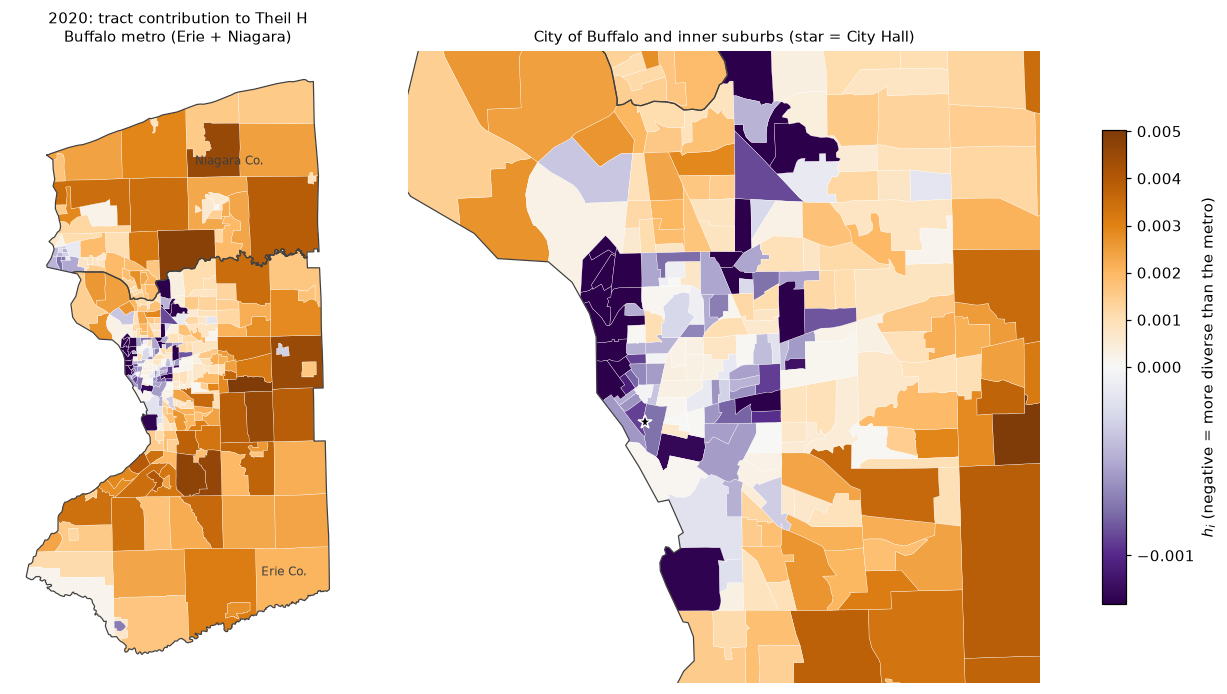

In [3]:
# ===================================================================
# Part B: Theil's information theory index $H$.
# The metro area has become much more diverse: Simpson diversity rises from 0.28 to 0.39 and
# ===================================================================

def theil_contributions(g, groups):
    c = g[groups].to_numpy(float)  # NumPy array view of the column
    t = c.sum(1); T = t.sum()  # sum the selected values
    P = c.sum(0) / T  # define P
    E = -(P * np.log(P)).sum()  # sum the selected values
    p = c / t[:, None]  # tract share of the focal group within the pair
    Ei = -np.sum(np.where(p > 0, p * np.log(p), 0), axis=1)  # define Ei
    return t * (E - Ei) / (T * E), Ei  # return the computed result

for y in YEARS:  # loop over panel years
    h_i, _ = theil_contributions(tracts[y], GROUPS)  # run this analysis or plotting step
    assert np.isclose(h_i.sum(), seg.theil_h(tracts[y], GROUPS))  # sanity-check an invariant
    print(f"{y}: H = {h_i.sum():.3f}; {(h_i < 0).sum()} of {len(h_i)} tracts are more diverse than the metro (h_i < 0)")  # status line for the notebook reader

h20, E20 = theil_contributions(tracts[2020], GROUPS)  # run this analysis or plotting step
lim = np.abs(h20).max()  # define lim
metro_and_core(tracts[2020], h20, title="2020: tract contribution to Theil H", cmap="PuOr_r",  # side-by-side metro and city-window choropleths
               norm=plt.matplotlib.colors.TwoSlopeNorm(vmin=-lim / 4, vcenter=0, vmax=lim),  # define norm
               label="$h_i$ (negative = more diverse than the metro)")  # define label
plt.show()  # render the figure in the notebook



The map is the opposite of what many people expect. The largest positive contributions come
from the **white suburban and rural ring**, not from the East Side. $H$ measures departure from
the metro mix, and in 2020 that mix is about 73% white. A 97% white suburban tract therefore departs
from it almost as much as an 85% Black city tract does, and there are many more such tracts with
large populations. East Side tracts contribute modestly, while the West Side and the areas around
downtown, where four groups live together, are *more* diverse than the metro and pull $H$ down
(purple). Segregation is a property of the whole region: the homogeneity of the suburbs is as much
part of it as the concentration of Black residents in the city.

How concentrated is segregation? Sorting tracts by $h_i$ shows what share of $H$ the most
segregated tracts account for.






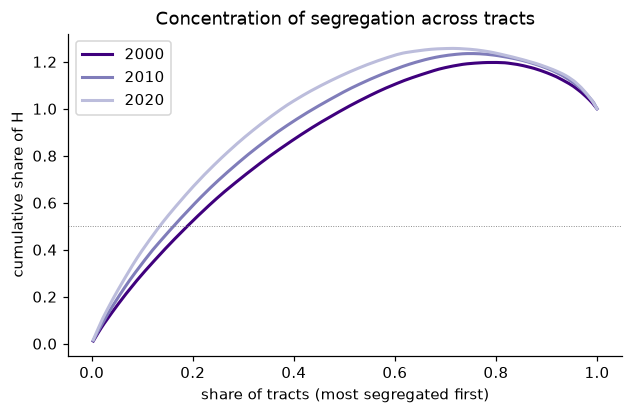

2000: 62 of 323 tracts account for half of H
2010: 53 of 323 tracts account for half of H
2020: 44 of 323 tracts account for half of H


In [4]:
# ===================================================================
# The map is the opposite of what many people expect. The largest positive contributions come
# ===================================================================

fig, ax = plt.subplots(figsize=(6.5, 3.8))  # create figure and axes
for y, col in zip(YEARS, ["#3f007d", "#807dba", "#bcbddc"]):  # loop over panel years  # iterate paired sequences together
    h_i, _ = theil_contributions(tracts[y], GROUPS)  # run this analysis or plotting step
    s = np.sort(h_i)[::-1]  # define s
    ax.plot(np.arange(1, len(s) + 1) / len(s), np.cumsum(s) / s.sum(), color=col, lw=2, label=str(y))  # draw geometries or a series on the axes
ax.axhline(0.5, color="gray", lw=0.6, ls=":")  # run this analysis or plotting step
ax.set(xlabel="share of tracts (most segregated first)", ylabel="cumulative share of H",  # set labels, title, or axis limits
       title="Concentration of segregation across tracts")  # define title
ax.legend(); plt.show()  # render the figure in the notebook
for y in YEARS:  # loop over panel years
    h_i, _ = theil_contributions(tracts[y], GROUPS)  # run this analysis or plotting step
    s = np.sort(h_i)[::-1]  # define s
    print(f"{y}: {np.searchsorted(np.cumsum(s) / s.sum(), 0.5) + 1} of {len(s)} tracts account for half of H")  # status line for the notebook reader



The number of tracts that produce half of $H$ falls from 62 to 44: the segregation that remains
is concentrated in fewer places, while more tracts (92 in 2020, up from 66 in 2000) are more
diverse than the metro as a whole.

## Part C: Multigroup dissimilarity

Sakoda's (1981) generalization of $D$ sums each tract's absolute deviation from the regional
composition over all groups and normalizes by the region's own Simpson interaction
$I_s = \sum_k P_k(1-P_k)$:

$$D_{multi} = \frac{\sum_i \sum_k t_i\,|p_{ik} - P_k|}{2\,T\,I_s}.$$

With only two groups this reduces to ordinary $D$ exactly, which the cell verifies.






In [5]:
# ===================================================================
# Part C: Multigroup dissimilarity.
# The number of tracts that produce half of $H$ falls from 62 to 44: the segregation that remains
# ===================================================================

for y, g in tracts.items():  # loop over each year and its tract GeoDataFrame
    print(f"{y}: two-group D = {seg.dissimilarity(g, ['black', 'white']):.6f}   "  # two-group dissimilarity index D
          f"multigroup D on the same 2 groups = {seg.multigroup_dissimilarity(g, ['black', 'white']):.6f}")  # field in the summary row

multi = pd.DataFrame({  # build table multi
    y: {"Theil H": seg.theil_h(g, GROUPS),  # run this analysis or plotting step
        "multigroup D": seg.multigroup_dissimilarity(g, GROUPS),  # field in the summary row
        "two-group D (Black, white)": seg.dissimilarity(g, ["black", "white"])}  # two-group dissimilarity index D
    for y, g in tracts.items()  # loop over each year and its tract GeoDataFrame
}).T
multi.round(3)  # round for readable display


2000: two-group D = 0.774057   multigroup D on the same 2 groups = 0.774057
2010: two-group D = 0.729950   multigroup D on the same 2 groups = 0.729950
2020: two-group D = 0.686749   multigroup D on the same 2 groups = 0.686749


,Theil H,multigroup D,"two-group D (Black, white)"
2000,0.434,0.678,0.774
2010,0.368,0.616,0.730
2020,0.306,0.555,0.687


$H$ is always smaller than $D_{multi}$ for the same data; they use different scales (entropy vs.
absolute deviation) and should be compared only across places or years, not with each other.
Reardon and Firebaugh (2002) recommend $H$ as the default multigroup measure because it satisfies
the principle of transfers and decomposes additively.

## Part D: The pairwise matrix

A multigroup index compresses six pairwise contrasts into one number. Showing the full
pairwise dissimilarity matrix alongside it tells the reader *which* groups drive it.






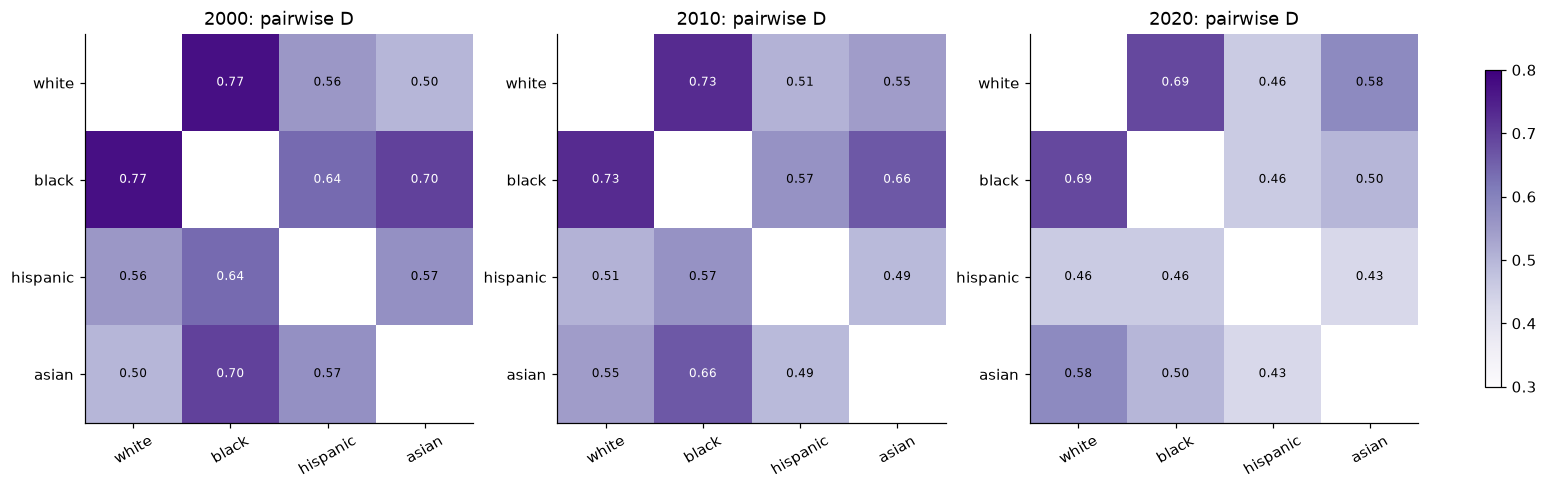

In [6]:
# ===================================================================
# Part D: The pairwise matrix.
# $H$ is always smaller than $D_{multi}$ for the same data; they use different scales (entropy vs.
# ===================================================================

def pairwise_matrix(g, groups, index_fn=seg.dissimilarity):
    M = pd.DataFrame(np.nan, index=groups, columns=groups)  # build table M
    for a in groups:  # loop over demographic groups
        for b in groups:  # loop over demographic groups
            if a != b:  # conditional branch
                M.loc[a, b] = index_fn(g, [a, b])  # assign a derived column or cell
    return M  # return the computed result

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), constrained_layout=True)  # create figure and axes
for ax, y in zip(axes, YEARS):  # loop over panel years
    M = pairwise_matrix(tracts[y], GROUPS)  # define M
    im = ax.imshow(M, cmap="Purples", vmin=0.3, vmax=0.8)  # define im
    ax.set_xticks(range(4), GROUPS, rotation=30); ax.set_yticks(range(4), GROUPS)  # label years on the x-axis
    for i in range(4):  # iterate over the collection
        for j in range(4):  # iterate over the collection
            if i != j:  # conditional branch
                ax.text(j, i, f"{M.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,  # run this analysis or plotting step
                        color="white" if M.iloc[i, j] > 0.6 else "black")  # define color
    ax.set_title(f"{y}: pairwise D")  # set labels, title, or axis limits
fig.colorbar(im, ax=axes, shrink=0.8); plt.show()  # render the figure in the notebook



In 2000 the matrix is dominated by the Black row: Black residents are highly separated from every
other group (0.64 to 0.77). By 2020 the Black-Hispanic and Black-Asian contrasts have fallen to
about 0.46 and 0.50, while the Asian-white contrast has risen to 0.59. Black-white remains the
largest pair, and the Asian row is the only one that grows. The multigroup indices hide these
opposing movements.

## Part E: Local diversity

PySAL's local multigroup measures map each tract's own diversity. `seg.local_entropy` and
`seg.local_simpson_diversity` return one value per tract; both are 0 in a single-group tract.
Comparing a tract's entropy with the regional entropy $E$ is exactly the quantity inside $H$.






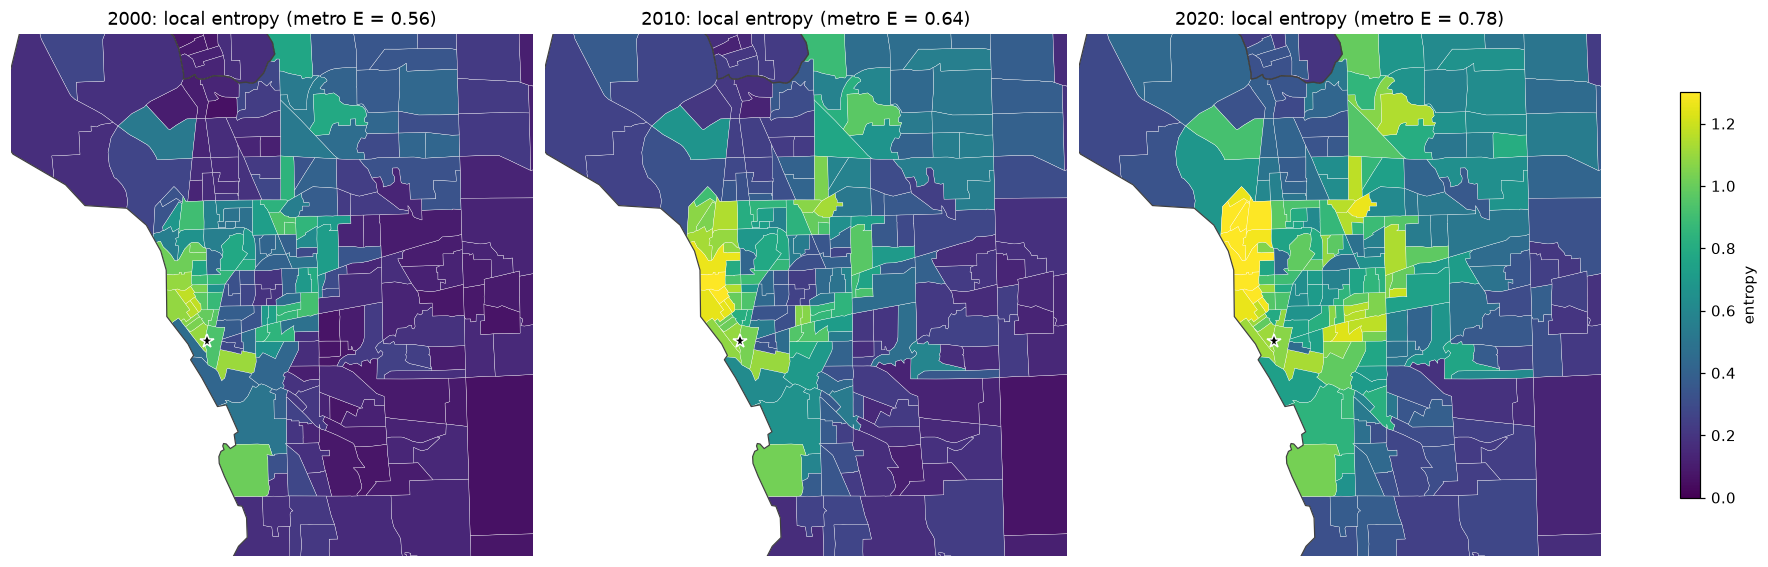

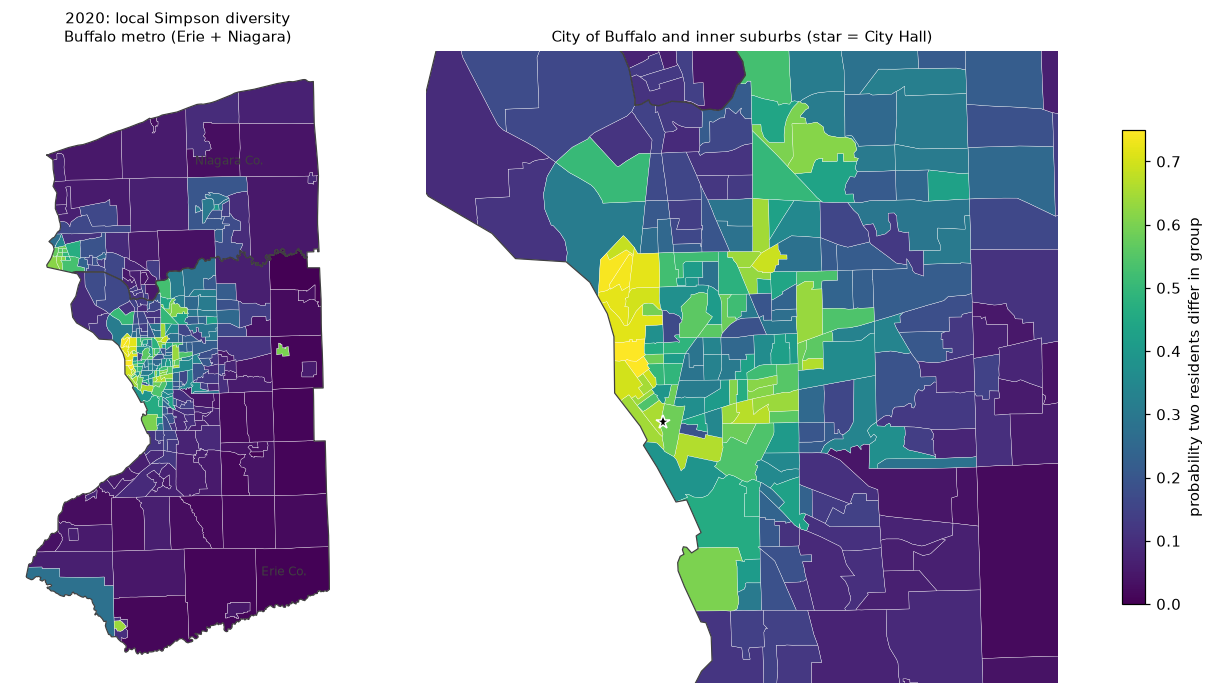

In [7]:
# ===================================================================
# Part E: Local diversity.
# In 2000 the matrix is dominated by the Black row: Black residents are highly separated from every
# ===================================================================

E_reg = {y: regional_entropy(g, GROUPS) for y, g in tracts.items()}  # define E_reg
fig, axes = plt.subplots(1, 3, figsize=(16, 5.4), constrained_layout=True)  # create figure and axes
for ax, y in zip(axes, YEARS):  # loop over panel years
    g = tracts[y]  # working copy of one year's tracts
    g.assign(v=seg.local_entropy(g, GROUPS)).plot(column="v", cmap="viridis", vmin=0, vmax=1.3, ax=ax,  # draw geometries or a series on the axes
                                                  edgecolor="white", linewidth=0.2)  # define edgecolor
    add_context(ax, core=True); ax.set_title(f"{y}: local entropy (metro E = {E_reg[y]:.2f})")  # county outlines and optional city zoom
fig.colorbar(plt.cm.ScalarMappable(cmap="viridis", norm=plt.Normalize(0, 1.3)), ax=axes, shrink=0.7, label="entropy")  # attach a colour bar to the figure
plt.show()  # render the figure in the notebook

g = tracts[2020]  # working copy of one year's tracts
metro_and_core(g, seg.local_simpson_diversity(g, GROUPS), title="2020: local Simpson diversity",  # side-by-side metro and city-window choropleths
               cmap="viridis", vmin=0, vmax=0.75, label="probability two residents differ in group")  # define cmap
plt.show()  # render the figure in the notebook



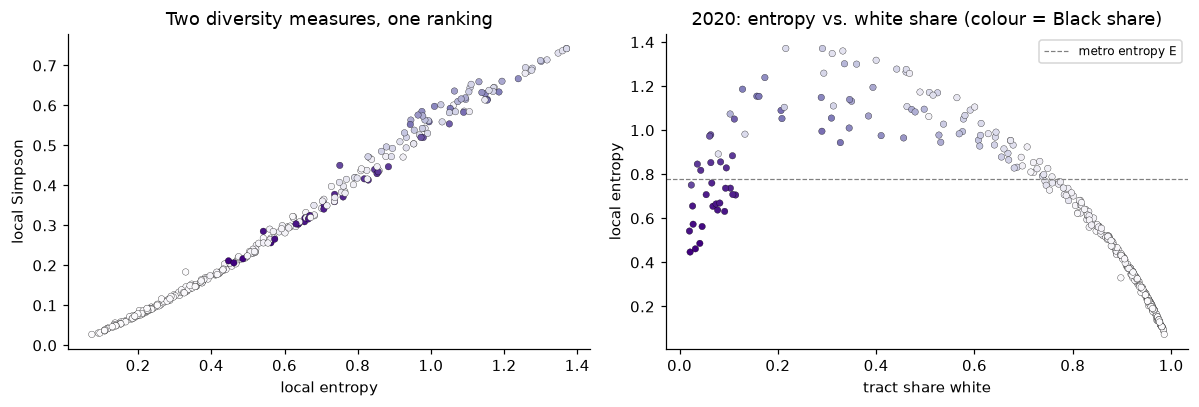

Spearman correlation entropy vs Simpson: 0.998
Most diverse tracts in 2020:


,tract_id,county,white,black,hispanic,asian,entropy
179,36029006901,Erie,877,876,1320,985,1.37
156,36029006100,Erie,1413,1370,1196,881,1.37
109,36029005802,Erie,1738,899,1364,1231,1.36
26,36029005700,Erie,1038,612,1092,600,1.35
102,36029005900,Erie,1521,728,983,571,1.32
155,36029017100,Erie,1706,1809,976,593,1.30


In [8]:
g = tracts[2020]  # working copy of one year's tracts
ent = seg.local_entropy(g, GROUPS)  # define ent
simp = seg.local_simpson_diversity(g, GROUPS)  # define simp
share_black = g.black / g[GROUPS].sum(axis=1)  # define share_black
share_white = g.white / g[GROUPS].sum(axis=1)  # define share_white
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))  # create figure and axes
axes[0].scatter(ent, simp, c=share_black, cmap="Purples", s=18, edgecolor="k", lw=0.2)  # run this analysis or plotting step
axes[0].set(xlabel="local entropy", ylabel="local Simpson", title="Two diversity measures, one ranking")  # set labels, title, or axis limits
axes[1].scatter(share_white, ent, c=share_black, cmap="Purples", s=18, edgecolor="k", lw=0.2)  # run this analysis or plotting step
axes[1].axhline(E_reg[2020], color="gray", ls="--", lw=0.8, label="metro entropy E")  # run this analysis or plotting step
axes[1].set(xlabel="tract share white", ylabel="local entropy", title="2020: entropy vs. white share (colour = Black share)")  # set labels, title, or axis limits
axes[1].legend(fontsize=8); plt.tight_layout(); plt.show()  # render the figure in the notebook
print(f"Spearman correlation entropy vs Simpson: {pd.Series(ent).corr(pd.Series(simp), method='spearman'):.3f}")  # status line for the notebook reader
print("Most diverse tracts in 2020:")  # status line for the notebook reader
display(g.assign(entropy=ent).nlargest(6, "entropy")[["tract_id", "county", *GROUPS, "entropy"]].round(2))  # show a rich table preview



Entropy and Simpson rank tracts almost identically (Spearman 0.998). The most diverse tracts are
on Buffalo's West Side and near downtown, where white, Black, Hispanic, and Asian residents are
present in similar numbers. Mostly white suburban tracts (right of the scatter plot) and mostly
Black East Side tracts (dark points, left) are both less diverse than the metro. Diversity is
highest where neither group dominates, and over twenty years the high-diversity area has spread
across more of the city.

## Part F: Spatial multigroup segregation

As with the single-group indices, pool each tract's counts over a kernel neighbourhood and
recompute $H$. The ratio $H(\text{bandwidth})/H(\text{aspatial})$ reads as "the share of
segregation that is still visible at that scale", the core idea behind Reardon et al.'s (2008)
macro/micro segregation comparison.






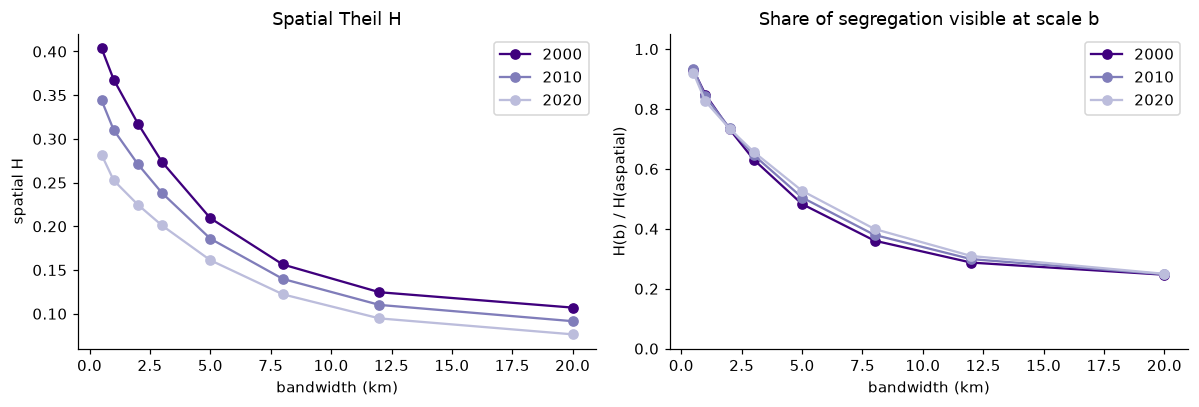

,500,1000,2000,3000,5000,8000,12000,20000
2000,0.93,0.85,0.73,0.63,0.48,0.36,0.29,0.25
2010,0.93,0.84,0.74,0.65,0.50,0.38,0.30,0.25
2020,0.92,0.83,0.73,0.66,0.53,0.40,0.31,0.25


In [9]:
# ===================================================================
# Part F: Spatial multigroup segregation.
# Entropy and Simpson rank tracts almost identically (Spearman 0.998). The most diverse tracts are
# ===================================================================

def pooled(g, groups, bandwidth):
    nb = seg.kernel_weights(g, bandwidth=bandwidth, kernel="gaussian")  # distance-decay neighbourhood weights
    out = g.copy()  # mutable copy so originals stay unchanged
    out[groups] = nb.pooled_counts(g[groups].to_numpy(float))  # assign a derived column or cell
    return out  # return the computed result

bws = [500, 1000, 2000, 3000, 5000, 8000, 12000, 20000]  # define bws
spatial_H = pd.DataFrame({y: [seg.theil_h(pooled(g, GROUPS, b), GROUPS) for b in bws]  # build table spatial_H
                          for y, g in tracts.items()}, index=bws)  # loop over each year and its tract GeoDataFrame
ratio = spatial_H / pd.Series({y: seg.theil_h(g, GROUPS) for y, g in tracts.items()})  # define ratio

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))  # create figure and axes
for y, col in zip(YEARS, ["#3f007d", "#807dba", "#bcbddc"]):  # loop over panel years  # iterate paired sequences together
    axes[0].plot(np.array(bws) / 1000, spatial_H[y], marker="o", color=col, label=str(y))  # draw geometries or a series on the axes
    axes[1].plot(np.array(bws) / 1000, ratio[y], marker="o", color=col, label=str(y))  # draw geometries or a series on the axes
axes[0].set(xlabel="bandwidth (km)", ylabel="spatial H", title="Spatial Theil H")  # set labels, title, or axis limits
axes[1].set(xlabel="bandwidth (km)", ylabel="H(b) / H(aspatial)", title="Share of segregation visible at scale b", ylim=(0, 1.05))  # set labels, title, or axis limits
for a in axes: a.legend()  # iterate over the collection
plt.tight_layout(); plt.show()  # render the figure in the notebook
ratio.round(2).T  # run this analysis or plotting step



The profiles are almost identical in all three years: a 2 km kernel keeps about 73% of $H$, 5 km
about half, and even 20 km about a quarter. The **level** of segregation fell, but its **scale**
did not change: what remains is still a large-scale city-suburb and East Side-versus-rest pattern.
If anything, in 2020 slightly more of $H$ survives at 5 to 8 km, meaning the decline happened a
little more at short range. Notebook 03_07_04 studies this scale structure directly.

## Part G: Validation against PySAL






In [10]:
# ===================================================================
# Part G: Validation against PySAL.
# The profiles are almost identical in all three years: a 2 km kernel keeps about 73% of $H$, 5 km
# ===================================================================

try:
    from segregation.multigroup import MultiDissim, MultiInfoTheory, SimpsonsInteraction  # library import used below
except ImportError:  # tell the reader how to install the optional dependency
    print("PySAL `segregation` not installed: pip install segregation to run this check")  # status line for the notebook reader
else:
    rows = []  # accumulate one summary row per year / group
    for y, g in tracts.items():  # loop over each year and its tract GeoDataFrame
        rows += [(y, "Theil H", MultiInfoTheory(g, groups=GROUPS).statistic, seg.theil_h(g, GROUPS)),  # append cross-check rows for this year
                 (y, "Multigroup D", MultiDissim(g, groups=GROUPS).statistic, seg.multigroup_dissimilarity(g, GROUPS)),  # run this analysis or plotting step
                 (y, "Simpson interaction", SimpsonsInteraction(g, groups=GROUPS).statistic, seg.simpson_diversity(g, GROUPS))]  # run this analysis or plotting step
    check = pd.DataFrame(rows, columns=["year", "index", "PySAL", "GeoLattice"])  # PySAL vs GeoLattice cross-check table
    check["abs diff"] = (check.PySAL - check.GeoLattice).abs()  # absolute gap between group share schedules
    display(check.round(6))  # show a rich table preview



PySAL `segregation` not installed: pip install segregation to run this check


## Part H: Reporting with uncertainty






In [11]:
# ===================================================================
# Part H: Reporting with uncertainty
# ===================================================================

rows = []  # accumulate one summary row per year / group
for y, g in tracts.items():  # loop over each year and its tract GeoDataFrame
    for name in ["theil_h", "multigroup_dissimilarity"]:  # iterate over the collection
        r = seg.compute(g, index=name, groups=GROUPS, ci=True, n_boot=299, n_blocks=30, seed=1)  # index with optional spatial-block bootstrap CI
        rows.append({"year": y, "index": name, "value": r.value, "95% CI": f"[{r.ci_lower:.3f}, {r.ci_upper:.3f}]"})  # append this year/group record
pd.DataFrame(rows).pivot(index="year", columns="index", values=["value", "95% CI"])  # run this analysis or plotting step



value                             95% CI  \
index multigroup_dissimilarity   theil_h multigroup_dissimilarity   
year                                                                
2000                  0.677902   0.43363           [0.523, 0.724]   
2010                  0.616283  0.368376           [0.485, 0.666]   
2020                  0.554863  0.305983           [0.458, 0.601]   

                       
index         theil_h  
year                   
2000   [0.230, 0.483]  
2010   [0.215, 0.425]  
2020   [0.206, 0.353]

## Summary

- **Diversity is not integration.** Metro-wide diversity rises as the population changes, while
  Theil's $H$ falls; the two answer different questions.
- **Theil's $H$** is a population-weighted entropy loss. Its tract contributions sum exactly to
  the metro value, so they can be mapped to show where segregation is produced.
- **Multigroup dissimilarity** reduces to the two-group $D$ for two groups. Report the
  pairwise matrix alongside any multigroup index so readers can see which contrasts drive it.
- **Local entropy and Simpson** map diversity; the most diverse tracts are not the same as the
  least segregated region.
- **Kernel-pooled $H$** shows how much segregation survives at larger scales, separating
  macro-scale divides from local patchiness.

**Next:** 03_07_03 moves from region-wide numbers to local measures with significance tests.

**Data:** U.S. Census Bureau, Decennial Census 2000, 2010, 2020, tract level, Erie and Niagara
counties, NY.

## References

- Reardon, S. F., & Firebaugh, G. (2002). Measures of multigroup segregation. *Sociological Methodology*, 32(1), 33-67.
- Reardon, S. F., Matthews, S. A., O'Sullivan, D., Lee, B. A., Firebaugh, G., Farrell, C. R., & Bischoff, K. (2008). The geographic scale of metropolitan racial segregation. *Demography*, 45(3), 489-514.
- Sakoda, J. M. (1981). A generalized index of dissimilarity. *Demography*, 18(2), 245-250.
- Theil, H., & Finizza, A. J. (1971). A note on the measurement of racial integration of schools by means of informational concepts. *Journal of Mathematical Sociology*, 1(2), 187-193.




